# Cleaning EDA: screening CISO demand

This notebook looks at the hourly demand that EIA-930 reports for the California ISO (`CISO`, type `D`), runs the screens in `gridcast.clean.screen`, and shows what they flag. It also compares reported demand with the operator's day-ahead forecast (`DF`), because that comparison turned up something the scoring in later milestones has to deal with.

It reads from the database loaded by `gridcast.jobs.ingest --backfill`. Nothing in the pipeline depends on this notebook.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import FancyBboxPatch

from gridcast import db
from gridcast.clean.screen import Flag, clean
from gridcast.config import LOCAL_TZ, Settings

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())

with db.connect(Settings(_env_file=ROOT / ".env").require_database_url()) as conn:
    reported = db.read_raw_demand(conn)
    rows = conn.execute(
        "select period_utc, value from raw_eia where respondent = 'CISO' and type = 'DF' "
        "order by period_utc"
    ).fetchall()

operator = pd.Series(
    [float(value) for _, value in rows],
    index=pd.to_datetime([period for period, _ in rows], utc=True),
    name="operator_forecast_mw",
)
print(f"Reported demand: {len(reported):,} hours, {reported.index.min():%Y-%m-%d} to {reported.index.max():%Y-%m-%d %H:%M} UTC")

Reported demand: 68,191 hours, 2019-01-01 to 2026-10-12 08:00 UTC


In [2]:
# Chart styling: one light surface, recessive grid, thin marks.
SURFACE, INK, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"
YEAR_RAMP = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"]  # one hue, light to dark

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.family": "sans-serif", "font.size": 10,
    "text.color": INK, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 1, "axes.axisbelow": True,
    "xtick.major.size": 0, "ytick.major.size": 0, "lines.linewidth": 2, "lines.solid_capstyle": "round",
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})

## Screening results

`clean` returns one row per hour with the screened value, a flag (empty when the hour passed every screen) and whether the value was filled in. Almost all flagged hours are in 2019; since 2020 it is a handful per year.

| Flag | Meaning |
|---|---|
| `missing` | The hour was never published, or was published empty |
| `non_positive` | Zero or negative |
| `global_outlier` | More than 10x above or below the overall median |
| `repeated_value` | The same value three or more times, each within a day of the last (a stuck feed) |
| `spike` | A jump of more than 4 rolling IQRs of the hourly change, reversed within 6 hours |
| `local_outlier_high` / `_low` | More than 1.5x above or below a rolling-median estimate |
| `anomalous_region` | A good-looking hour with more than 15% of the surrounding 24 hours flagged |

In [3]:
cleaned = clean(reported)
flags = cleaned["flag"]
year = cleaned.index.year

by_year = pd.crosstab(year, flags.fillna("ok")).drop(columns="ok").rename_axis(index="year", columns=None)
by_year.insert(0, "hours", cleaned.groupby(year).size())
by_year.insert(1, "flagged", flags.notna().groupby(year).sum())
by_year.insert(2, "% flagged", (flags.notna().groupby(year).mean() * 100).round(3))
by_year.loc["all"] = by_year.sum()
by_year.loc["all", "% flagged"] = round(flags.notna().mean() * 100, 3)
by_year.astype({column: int for column in by_year.columns if column != "% flagged"})

,hours,flagged,% flagged,anomalous_region,global_outlier,missing,repeated_value,spike
year,,,,,,,,
2019,8760,101,1.153,54,3,10,14,20
2020,8784,4,0.046,0,0,3,0,1
2021,8760,6,0.068,0,0,6,0,0
2022,8760,3,0.034,0,0,3,0,0
2023,8760,2,0.023,0,0,2,0,0
2024,8784,0,0.000,0,0,0,0,0
2025,8760,4,0.046,0,0,0,3,1
2026,6825,2,0.029,0,0,0,0,2
all,68193,122,0.179,54,3,24,17,24


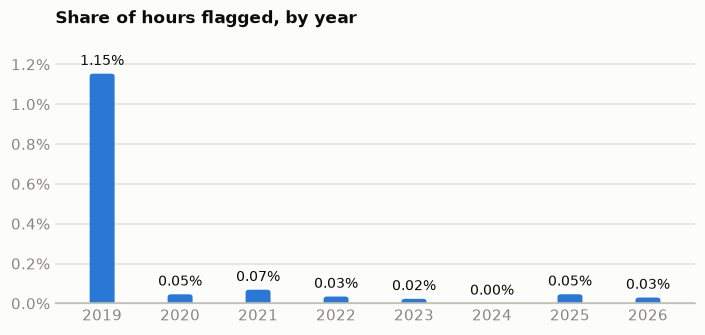

In [4]:
share = flags.notna().groupby(year).mean() * 100

fig, ax = plt.subplots(figsize=(7.5, 3.2))
top = share.max() * 1.18
for position, value in enumerate(share):
    # Rounded at the data end, square at the baseline (the box extends below zero and is clipped).
    bar = FancyBboxPatch(
        (position - 0.16, -top), 0.32, value + top,
        boxstyle="round,pad=0,rounding_size=0.045", mutation_aspect=top / 4.6,
        facecolor=BLUE, edgecolor="none", clip_on=True,
    )
    ax.add_patch(bar)
    ax.text(position, value + top * 0.02, f"{value:.2f}%", ha="center", va="bottom", color=INK, fontsize=9)
ax.set_xlim(-0.6, len(share) - 0.4)
ax.set_ylim(0, top)
ax.set_xticks(range(len(share)), share.index)
ax.yaxis.set_major_formatter(lambda value, _: f"{value:.1f}%")
ax.axhline(0, color=AXIS, linewidth=1)
ax.set_title("Share of hours flagged, by year")
plt.show()

## What the flagged hours look like

Four episodes, one per kind of problem. The gray bands mark flagged hours, which later milestones skip when scoring. Each panel has its own vertical scale.

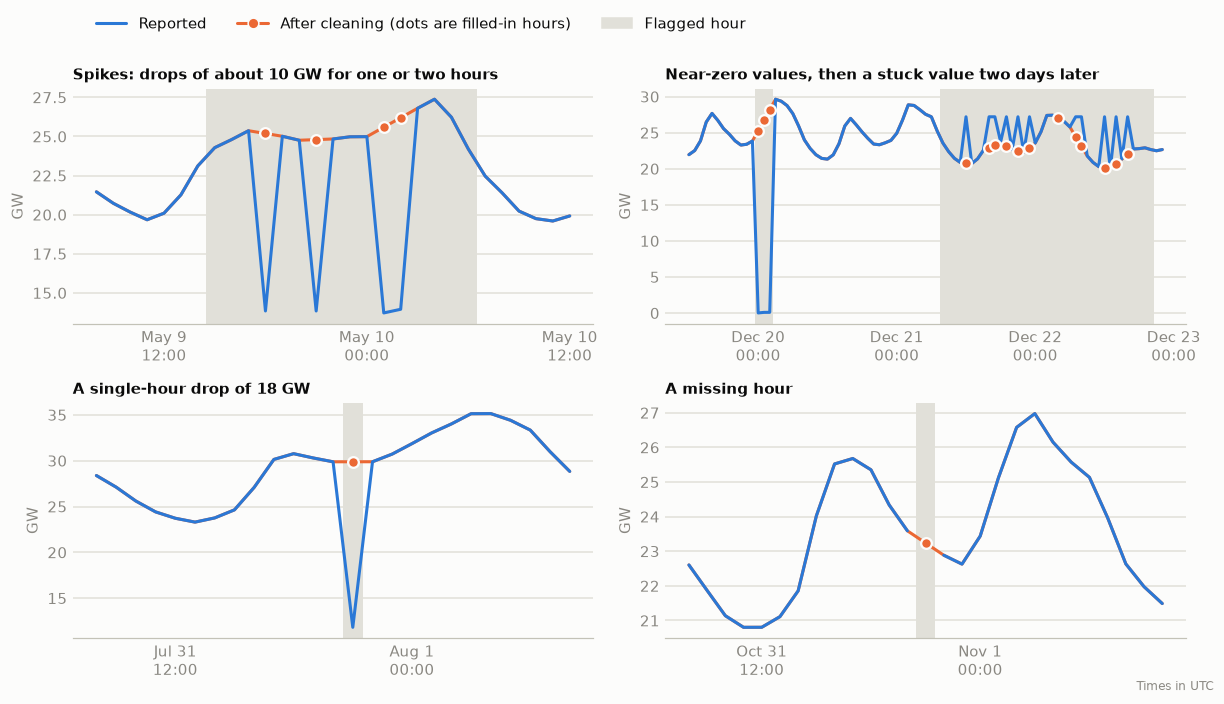

In [5]:
episodes = [
    ("Spikes: drops of about 10 GW for one or two hours", "2019-05-09 08:00", "2019-05-10 12:00"),
    ("Near-zero values, then a stuck value two days later", "2019-12-19 12:00", "2019-12-22 22:00"),
    ("A single-hour drop of 18 GW", "2025-07-31 08:00", "2025-08-01 08:00"),
    ("A missing hour", "2023-10-31 08:00", "2023-11-01 10:00"),
]

fig, axes = plt.subplots(2, 2, figsize=(11, 6.4))
for ax, (title, start, end) in zip(axes.flat, episodes):
    window = cleaned.loc[start:end]
    raw = reported.reindex(window.index) / 1000
    for hour in window.index[window["flag"].notna()]:
        ax.axvspan(hour - pd.Timedelta(minutes=30), hour + pd.Timedelta(minutes=30), color="#e1e0d9", linewidth=0)
    ax.plot(window.index, window["demand_mw"] / 1000, color=ORANGE)
    ax.plot(raw.index, raw, color=BLUE)
    imputed = window[window["imputed"]]
    ax.plot(imputed.index, imputed["demand_mw"] / 1000, "o", color=ORANGE, markersize=7,
            markeredgecolor=SURFACE, markeredgewidth=1.5)
    ax.set_title(title, fontsize=10)
    ax.set_ylim(bottom=min(0, ax.get_ylim()[0]) if raw.min() < 5 else None)
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=3, maxticks=5))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %-d\n%H:%M"))
    ax.set_ylabel("GW")

handles = [
    plt.Line2D([], [], color=BLUE, label="Reported"),
    plt.Line2D([], [], color=ORANGE, marker="o", markersize=7, markeredgecolor=SURFACE, label="After cleaning (dots are filled-in hours)"),
    plt.Rectangle((0, 0), 1, 1, color="#e1e0d9", label="Flagged hour"),
]
fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.06, 0.985), ncols=3)
fig.suptitle("")
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.text(0.995, 0.005, "Times in UTC", ha="right", va="bottom", color=MUTED, fontsize=8)
plt.show()

In [6]:
examples = cleaned[flags.notna()].assign(reported_mw=reported.reindex(cleaned.index)[flags.notna()])
examples = examples[["flag", "reported_mw", "demand_mw", "imputed"]].round(0)
examples.groupby("flag").head(3).sort_values("flag")

,flag,reported_mw,demand_mw,imputed
period_utc,,,,
2019-02-14 13:00:00+00:00,anomalous_region,21853.0,21853.0,False
2019-02-14 14:00:00+00:00,anomalous_region,22653.0,22653.0,False
2019-02-14 15:00:00+00:00,anomalous_region,23968.0,23968.0,False
2019-12-20 00:00:00+00:00,global_outlier,14.0,25292.0,True
2019-12-20 01:00:00+00:00,global_outlier,91.0,26740.0,True
2019-12-20 02:00:00+00:00,global_outlier,96.0,28188.0,True
2019-02-02 14:00:00+00:00,missing,NaN,20632.0,True
2019-02-06 14:00:00+00:00,missing,NaN,23832.0,True
2019-06-28 13:00:00+00:00,missing,NaN,22330.0,True


## How good is the filled-in value?

Every real gap in this series is a single hour. To measure the fill, hide 500 random good hours, clean the series again, and compare what comes back with what was hidden. A second run hides fifty 8-hour blocks, which exercises the longer-gap method that copies last week's shape.

In [7]:
rng = np.random.default_rng(0)
good = np.flatnonzero(flags.isna().to_numpy())
good = good[(good > 24 * 14) & (good < len(cleaned) - 24)]

def fill_error(positions: np.ndarray) -> pd.Series:
    hidden = cleaned["demand_mw"].copy()
    hidden.iloc[positions] = np.nan
    refilled = clean(hidden)["demand_mw"].iloc[positions]
    truth = cleaned["demand_mw"].iloc[positions]
    return ((refilled - truth).abs() / truth * 100).dropna()

single = fill_error(rng.choice(good, 500, replace=False))
starts = rng.choice(good[good % 24 == 0], 50, replace=False)
blocks = fill_error(np.concatenate([np.arange(start, start + 8) for start in starts]))

pd.DataFrame(
    {"hidden hours": [len(single), len(blocks)],
     "mean abs % error": [single.mean(), blocks.mean()],
     "95th percentile": [single.quantile(0.95), blocks.quantile(0.95)]},
    index=["single hours (interpolated)", "8-hour blocks (last week's shape)"],
).round(2)

,hidden hours,mean abs % error,95th percentile
single hours (interpolated),500,1.09,2.83
8-hour blocks (last week's shape),392,2.79,8.38


## Reported demand and the operator's forecast are drifting apart at midday

The project scores forecasts against reported demand (`D`) and compares them with the operator's forecast (`DF`). That only works if the two series describe the same quantity. Until about 2021 they did: the average gap is within a few hundred MW at every hour. From 2023 a gap opens in the middle of the day and grows every year.

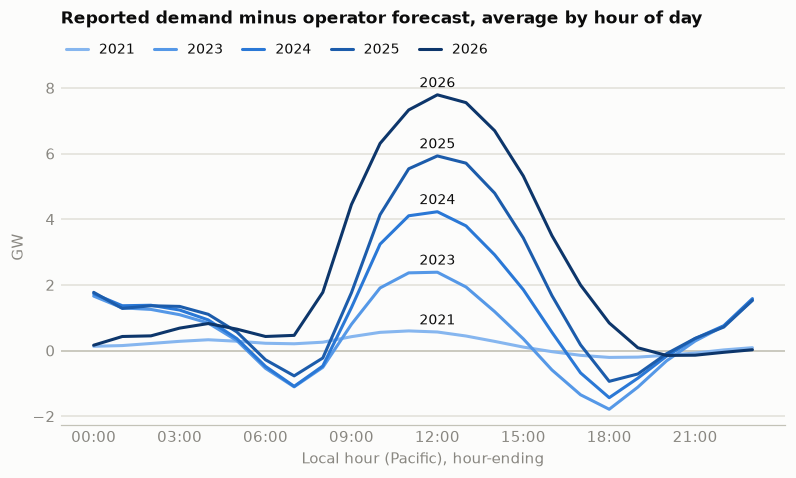

In [8]:
both = pd.DataFrame({"reported": cleaned["demand_mw"].where(flags.isna()), "operator": operator}).dropna()
local = both.index.tz_convert(LOCAL_TZ)
both["year"], both["hour"] = local.year, local.hour
both = both[both["year"] >= 2019]  # drops the few hours that fall on 2018-12-31 local time
both["gap_gw"] = (both["reported"] - both["operator"]) / 1000
both["abs_pct_error"] = (both["reported"] - both["operator"]).abs() / both["reported"] * 100

years = [2021, 2023, 2024, 2025, 2026]
profile = both[both["year"].isin(years)].pivot_table(index="hour", columns="year", values="gap_gw", aggfunc="mean")

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.axhline(0, color=AXIS, linewidth=1)
for color, selected in zip(YEAR_RAMP, years):
    ax.plot(profile.index, profile[selected], color=color, label=str(selected))
    peak_hour = 12
    ax.annotate(str(selected), (peak_hour, profile.loc[peak_hour, selected]), xytext=(0, 5),
                textcoords="offset points", ha="center", color=INK, fontsize=9)
ax.set_xticks(range(0, 24, 3), [f"{hour:02d}:00" for hour in range(0, 24, 3)])
ax.set_xlabel("Local hour (Pacific), hour-ending")
ax.set_ylabel("GW")
ax.set_title("Reported demand minus operator forecast, average by hour of day", pad=30)
ax.legend(loc="lower left", ncols=5, bbox_to_anchor=(-0.01, 1.0), fontsize=9, handlelength=1.6, columnspacing=1.4)
ax.set_ylim(top=profile.max().max() * 1.1)
plt.show()

In [9]:
midday = both["hour"].between(9, 16)
pd.DataFrame({
    "all hours": both.groupby("year")["abs_pct_error"].mean(),
    "09:00-16:00 local": both[midday].groupby("year")["abs_pct_error"].mean(),
    "other hours": both[~midday].groupby("year")["abs_pct_error"].mean(),
}).round(2).rename_axis("Operator forecast MAPE vs reported demand, %", axis="columns")

"Operator forecast MAPE vs reported demand, %",all hours,09:00-16:00 local,other hours
year,,,
2019,4.05,4.63,3.77
2020,2.31,2.74,2.10
2021,2.09,2.84,1.72
2022,3.56,4.49,3.09
2023,5.50,7.63,4.44
2024,6.97,12.30,4.31
2025,8.15,16.08,4.19
2026,9.14,21.55,2.95


In 2026 the operator's forecast is about 7 GW below reported demand at midday on average, and its error against reported demand is 21% in those hours against 3% in the rest of the day. An operator does not miss its own midday load by a fifth every day, so the likelier reading is that the two series no longer measure the same thing. The shape (daylight hours only, growing year on year) would fit battery charging being counted in reported demand but not in the forecast; that explanation is a guess and is not verified here.

Whatever the cause, scoring the operator's forecast against `D` as-is would make it look far worse than it is, and beating it would mean little. This needs a decision before the baselines in M3 are scored.

## Gaps in the operator's forecast

The operator's forecast is missing for whole days around daylight-saving transitions since 2024. Those days cannot be used for the head-to-head comparison.

In [10]:
hourly = operator.reindex(pd.date_range(operator.index.min(), operator.index.max(), freq="h"))
absent = hourly.isna()
run_id = absent.ne(absent.shift()).cumsum()[absent]
gaps = pd.DataFrame({
    "first missing hour (UTC)": run_id.groupby(run_id).apply(lambda run: run.index[0]),
    "hours": run_id.groupby(run_id).size(),
}).reset_index(drop=True)
gaps["first missing hour (UTC)"] = gaps["first missing hour (UTC)"].dt.strftime("%Y-%m-%d %H:%M")
gaps

,first missing hour (UTC),hours
0,2024-11-02 08:00,49
1,2025-03-09 09:00,23
2,2025-11-02 08:00,25
3,2026-03-08 09:00,23


## Takeaways

- Reported demand is nearly complete. The screens flag well under 1% of hours, and almost all of those are in 2019.
- The problems are short: single missing hours, drops to roughly 55% of the true level for one to four hours, three near-zero hours, and two episodes of a stuck value.
- The thresholds are loose on purpose. A first version using the IQR-based local filter from Ruggles et al. flagged about 5% of hours, most of them ordinary weekend middays where reported demand matched the operator's forecast.
- Filled-in single hours are close to the truth, so they are safe to use for lag features. They are never used for scoring.
- Reported demand and the operator's forecast have diverged at midday since 2023, which has to be resolved before the two are compared.